# Régression polynomiale avec NumPy

## Création des données

In [1]:
from IPython.display import HTML, display
import matplotlib.pyplot as plt
import more_itertools
import numpy
from numpy.polynomial import Polynomial

# On fixe la graine du générateur afin d'avoir des résultats reproductibles
rng = numpy.random.default_rng(2020)

# Génération de 1000 nombres aléatoires distribués selon la loi normale X ~ N(5, 1)
x = rng.normal(5, 1.0, 1000)

# Cibles : du bruit gaussien N(50, 10²) divisé par x, auquel on ajoute x²
y = rng.normal(50.0, 10.0, 1000) / x + x**2

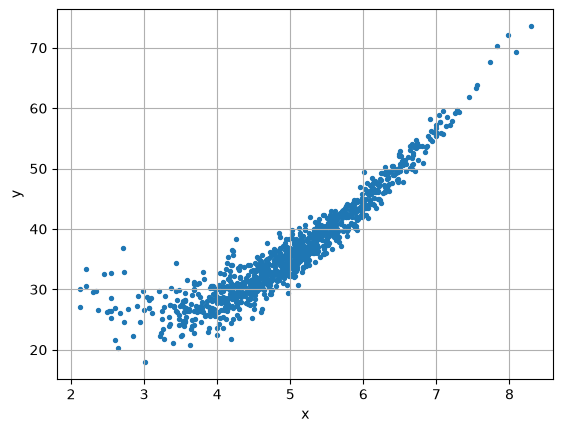

In [2]:
axes = plt.axes()
axes.grid()
plt.xlabel("x")
plt.ylabel("y")
plt.scatter(x, y, s=8)
plt.show()

## Jeu d'apprentissage et jeu de test

On n'apprend que sur 100 points : avec si peu de données, le sur-apprentissage se voit. Les 900 autres points ne servent qu'à mesurer l'erreur sur des données jamais vues.

In [3]:
# On mélange les indices, puis on garde les 100 premiers pour apprendre
indices = rng.permutation(len(x))
train, test = indices[:100], indices[100:]

x_train, y_train = x[train], y[train]
x_test, y_test = x[test], y[test]

## Définition d'une fonction pour représenter un polynôme

Prend un polynôme (de type `numpy.polynomial.Polynomial`) et l'affiche.

In [4]:
def terme_html(puissance: int, coeff: float) -> tuple[str, bool]:
  texte = f"{abs(coeff):.3f}"
  if puissance >= 1:
    texte += "𝑥"
    if puissance > 1:
      texte += f"<sup>{puissance}</sup>"
  return texte, coeff >= 0


def affiche_equation(poly: Polynomial) -> None:
  # Les coefficients sont dans l'échelle de x (et non dans [-1, 1])
  coeffs = poly.convert().coef
  termes_html, positifs = zip(
    *(terme_html(k, c) for k, c in reversed(list(enumerate(coeffs))))
  )
  liaisons = [" + " if signe else " - " for signe in positifs[1:]]
  termes = "".join(more_itertools.interleave_longest(termes_html, liaisons))
  display(HTML(f"𝑦 = {termes}"))

## Apprentissage des paramètres de notre polynôme

Les slides de la régression linéaire minimisent l'erreur $E$ par descente de gradient. `Polynomial.fit` minimise la même erreur (les moindres carrés), mais la résout directement, sans itérer : un polynôme de degré $d$ est une régression linéaire sur $x, x^2, \dots, x^d$ (voir « Une régression linéaire déguisée »), dont les poids $w_k$ ont une solution exacte. Pour que $x^d$ n'explose pas, `Polynomial.fit` ramène d'abord $x$ dans $[-1, 1]$, comme la mise à l'échelle du pipeline des slides.

In [5]:
def apprend_poly(x: numpy.ndarray, y: numpy.ndarray, d: int) -> Polynomial:
  # Polynomial.fit trouve les paramètres optimaux d'un polynôme de degré d
  # au sens des moindres carrés, tels que y ≈ poly(x)
  return Polynomial.fit(x, y, d)


poly = apprend_poly(x_train, y_train, 2)
# Coefficients appris, du degré 0 (b) au degré 2 (w₂)
poly.convert().coef

array([39.89932218, -9.94004906,  1.77154304])

## Affichage final

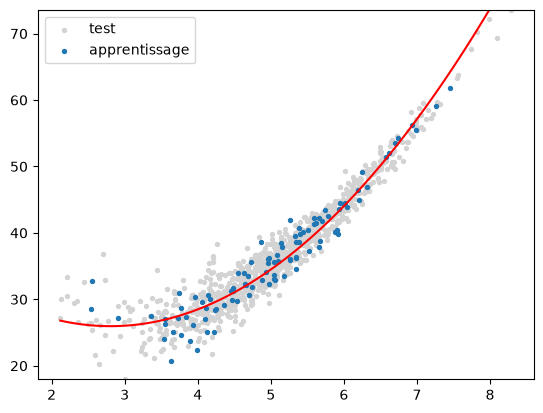

In [6]:
def affiche_poly(poly: Polynomial) -> None:
  # Calcul de la fonction apprise sur plusieurs points
  x_courbe = numpy.linspace(x.min(), x.max(), 1000)

  # Affichage de la courbe apprise
  plt.plot(x_courbe, poly(x_courbe), c="r")

  # Superposition des points d'apprentissage et de test
  plt.scatter(x_test, y_test, c="lightgray", s=8, label="test")
  plt.scatter(x_train, y_train, s=8, label="apprentissage")
  plt.ylim(y.min(), y.max())
  plt.legend()
  plt.show()


# Affichage du polynôme dans un format lisible
affiche_equation(poly)
affiche_poly(poly)

## Sous-apprentissage et sur-apprentissage

Les mêmes données avec les degrés $d = 1$, $2$ et $12$, appris sur les 100 points d'apprentissage (en couleur) : les points de test (en gris) montrent ce que le modèle n'a pas vu.

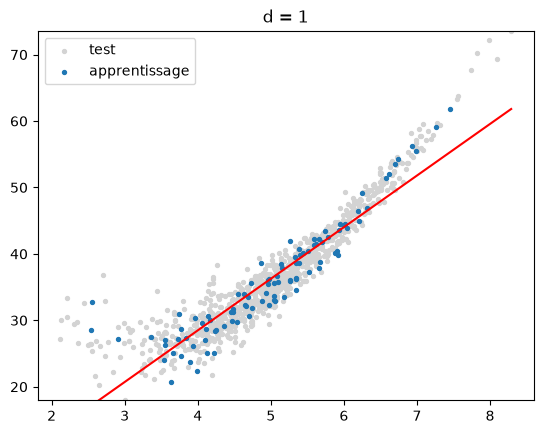

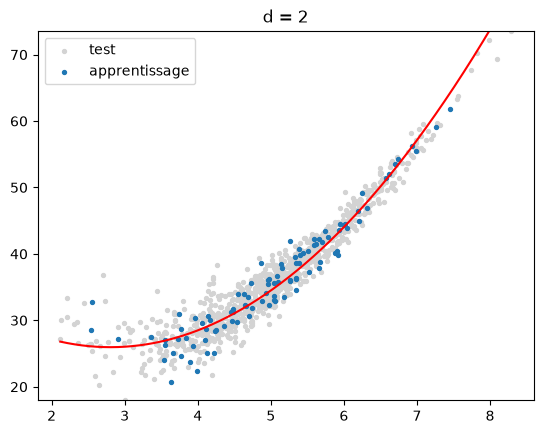

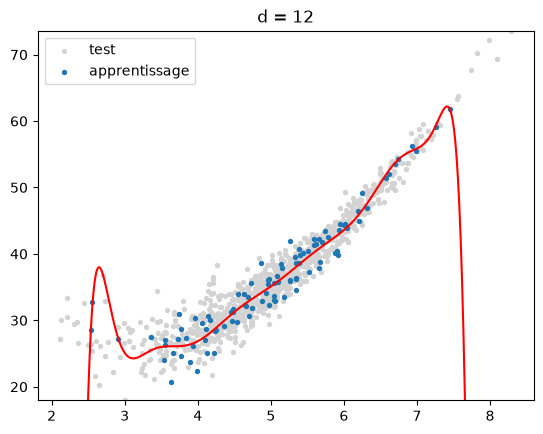

In [7]:
def apprend_et_affiche_poly(x: numpy.ndarray, y: numpy.ndarray, d: int) -> None:
  poly = apprend_poly(x, y, d)
  plt.title(f"d = {d}")
  affiche_poly(poly)


for d in (1, 2, 12):
  apprend_et_affiche_poly(x_train, y_train, d)

## Erreur selon le degré

On apprend un polynôme pour chaque degré de 1 à 12, puis on mesure l'erreur quadratique moyenne sur les deux jeux (échelle logarithmique).

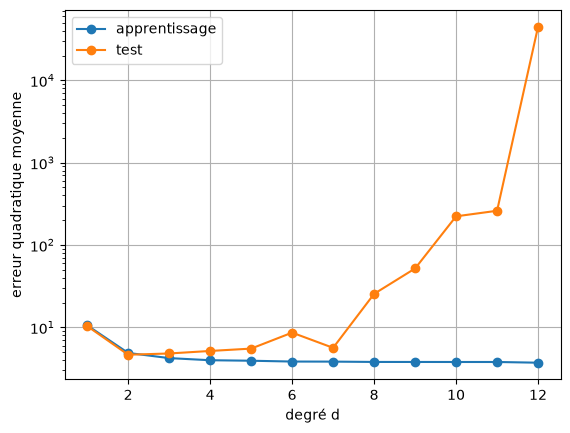

In [8]:
def eqm(poly: Polynomial, x: numpy.ndarray, y: numpy.ndarray) -> float:
  # Erreur quadratique moyenne
  return float(numpy.mean((poly(x) - y) ** 2))


degres = range(1, 13)
erreurs_train, erreurs_test = [], []
for d in degres:
  poly = apprend_poly(x_train, y_train, d)
  erreurs_train.append(eqm(poly, x_train, y_train))
  erreurs_test.append(eqm(poly, x_test, y_test))

plt.semilogy(degres, erreurs_train, "o-", label="apprentissage")
plt.semilogy(degres, erreurs_test, "o-", label="test")
plt.xlabel("degré d")
plt.ylabel("erreur quadratique moyenne")
plt.grid()
plt.legend()
plt.show()

**Conclusion** : à $d = 1$, la droite sous-apprend (l'erreur est élevée sur les deux jeux). À partir de $d = 2$, l'erreur d'apprentissage baisse de moins en moins, alors que l'erreur de test remonte, puis explose. Sur les 883 points de test compris dans l'intervalle des $x$ d'apprentissage, elle ne passe que d'environ 4,5 à 5,7 entre les degrés 2 et 12 : le polynôme apprend un peu du bruit des 100 points (sur-apprentissage). L'explosion vient surtout des 17 points de test qui sortent de cet intervalle, dont l'erreur quadratique moyenne dépasse deux millions au degré 12 : hors des données vues, un polynôme de haut degré part vers l'infini, il *extrapole* mal. On choisit donc $d$ sur des données qu'on n'a pas utilisées pour apprendre, ou on régularise (« Régularisation » dans les slides).